# V2D Challenge Track 2 - Noise Propagation and CPU Retargeting Feasibility

This notebook treats tier 1 and tier 2 as a paired data-layer experiment. It quantifies acceleration, plane penetration, and contact-timing changes, then runs a small Pinocchio CPU feasibility check against the bundled G1 URDF. It does not run Isaac Lab simulation or policy training.

### Setup and paired episode inventory

**What it does.** Reads both tier directories and verifies matching episode order and asset coverage.

**Input.** Track 2 metadata and Parquets.

**Output.** `outputs/track2_paired_inventory.json`.

**References.** Track 2 README.

In [3]:
from pathlib import Path
import json, sys, time, platform, subprocess, importlib.util
import matplotlib; matplotlib.use('Agg', force=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'v2d_cpu_utils.py').exists(): ROOT=Path('/Users/luran/Desktop/V2D_Challenge')
sys.path.insert(0,str(ROOT))
from v2d_cpu_utils import *
paths=ensure_outputs()
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'font.size':9})

t21=track2_paths(1); t22=track2_paths(2); assert [r['episode_index'] for r in t21]==[r['episode_index'] for r in t22]; inv=[]
for a,b in zip(t21,t22): inv.append({'episode_index':a['episode_index'],'sequence_id':a['sequence_id'],'object':a['object'],'tier1_rows':len(read_parquet(a['parquet'])),'tier2_rows':len(read_parquet(b['parquet'])),'mesh_exists':(ROOT/'video_to_data_challenge/track_2/tier_1_multiview_caption'/a['mesh']).exists(),'ground_plane_exists':(ROOT/'video_to_data_challenge/track_2/tier_1_multiview_caption'/a['ground_plane']).exists(),'support_surface_exists':(ROOT/'video_to_data_challenge/track_2/tier_1_multiview_caption'/a['support_surface']).exists()})
write_json(paths['root']/'track2_paired_inventory.json',inv); invdf=pd.DataFrame(inv); display(invdf.head(8)); print('paired episodes',len(invdf),'same-order rows',bool((invdf.tier1_rows==invdf.tier2_rows).all()))

paired episodes 30 same-order rows True


,episode_index,sequence_id,object,tier1_rows,tier2_rows,mesh_exists,ground_plane_exists,support_surface_exists
0,0,2026-06-04_14-16-23_tall_bar_stool_tip_up_04,tall_bar_stool,778,778,True,True,True
1,1,2026-05-18_17-06-21_vacuum_left_lean_02,vacuum,747,747,True,True,True
2,2,2026-06-02_10-04-42_blue_easter_basket_place_10,blue_easter_basket,980,980,True,True,True
3,3,2026-04-27_11-50-10_contigo_coffee_mug_handle_...,contigo_coffee_mug,781,781,True,True,True
4,4,2026-04-24_11-40-52_baseball_bat_rotate_05,baseball_bat,803,803,True,True,True
5,5,2026-03-18_19-36-56_g1_box_rotate_01,big_black_box,1003,1003,True,True,True
6,6,2026-06-01_11-26-44_monitor_rotate_05,monitor,546,546,True,True,True
7,7,2026-05-29_15-20-43_iron_round_table_02,iron,896,896,True,True,True


### Trajectory error propagation metrics

**What it does.** For every paired episode, computes position/orientation noise, raw and smoothed second-difference acceleration, ground-plane signed distance, penetration proxy, and contact-frame shift.

**Input.** Tier 1/tier 2 object poses, human translation columns, and ground-plane JSON.

**Output.** `outputs/report/track2_noise_summary.csv`, `outputs/metrics/track2_frame_metrics.csv`.

**References.** V2D Track 2 tier definitions; Savitzky and Golay, Analytical Chemistry 1964.

In [5]:
from pathlib import Path
import json, sys, time, platform, subprocess, importlib.util
import matplotlib; matplotlib.use('Agg', force=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'v2d_cpu_utils.py').exists(): ROOT=Path('/Users/luran/Desktop/V2D_Challenge')
sys.path.insert(0,str(ROOT))
from v2d_cpu_utils import *
paths=ensure_outputs()
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'font.size':9})

def plane_for(r):
 d=json.loads((ROOT/'video_to_data_challenge/track_2/tier_1_multiview_caption'/r['ground_plane']).read_text()); c=d.get('plane',d.get('coefficients',d.get('ground_plane',[0,0,1,0]))); return [c.get(k,0) for k in ('a','b','c','d')] if isinstance(c,dict) else c
def contact(z,v):
 h=np.where((np.abs(z)<.02)&(v<.08))[0]; return int(h[0]) if len(h) else None
fr=[]; sm=[]; fps=30.0
for a,b in zip(t21,t22):
 d1=read_parquet(a['parquet']); d2=read_parquet(b['parquet']); n=min(len(d1),len(d2)); p1=np.vstack(d1['observation.object.pose'].to_numpy())[:n]; p2=np.vstack(d2['observation.object.pose'].to_numpy())[:n]; te=np.linalg.norm(p2[:,:3]-p1[:,:3],axis=1); re=np.degrees(quat_angle_rad(p2[:,3:],p1[:,3:])); r1=np.linalg.norm(finite_difference(p1[:,:3],1/fps,2),axis=1); r2=np.linalg.norm(finite_difference(p2[:,:3],1/fps,2),axis=1); s1=np.linalg.norm(finite_difference(smooth_signal(p1[:,:3]),1/fps,2),axis=1); s2=np.linalg.norm(finite_difference(smooth_signal(p2[:,:3]),1/fps,2),axis=1); plane=plane_for(a); z1=plane_signed_distance(p1[:,:3],plane); z2=plane_signed_distance(p2[:,:3],plane); v1=np.linalg.norm(finite_difference(p1[:,:3],1/fps,1),axis=1); v2=np.linalg.norm(finite_difference(p2[:,:3],1/fps,1),axis=1); c1=contact(z1,v1); c2=contact(z2,v2)
 for i in range(n): fr.append({'episode_index':a['episode_index'],'object':a['object'],'frame':i,'translation_noise_m':float(te[i]),'orientation_noise_deg':float(re[i]),'accel_tier1_m_s2':float(r1[i]),'accel_tier2_m_s2':float(r2[i]),'accel_tier1_smooth_m_s2':float(s1[i]),'accel_tier2_smooth_m_s2':float(s2[i]),'plane_tier1_m':float(z1[i]),'plane_tier2_m':float(z2[i])})
 sm.append({'episode_index':a['episode_index'],'object':a['object'],'mean_translation_noise_m':float(np.mean(te)),'p95_translation_noise_m':float(np.percentile(te,95)),'mean_orientation_noise_deg':float(np.mean(re)),'acceleration_amplification_raw_x':float(np.mean(r2)/(np.mean(r1)+1e-9)),'acceleration_amplification_smoothed_x':float(np.mean(s2)/(np.mean(s1)+1e-9)),'penetration_tier1_frames':int(np.sum(z1<0)),'penetration_tier2_frames':int(np.sum(z2<0)),'penetration_delta_frames':int(np.sum(z2<0)-np.sum(z1<0)),'contact_frame_tier1':c1,'contact_frame_tier2':c2,'contact_shift_frames':(c2-c1 if c1 is not None and c2 is not None else None)})
frdf=pd.DataFrame(fr); sdf=pd.DataFrame(sm); frdf.to_csv(paths['metrics']/'track2_frame_metrics.csv',index=False); sdf.to_csv(paths['report']/'track2_noise_summary.csv',index=False); display(sdf.describe(include='all').T.head(14)); print('Median raw acceleration amplification',f"{sdf.acceleration_amplification_raw_x.median():.2f}x",'| smoothed',f"{sdf.acceleration_amplification_smoothed_x.median():.2f}x",'| median penetration delta',f"{sdf.penetration_delta_frames.median():.1f} frames")

Median raw acceleration amplification 1.78x | smoothed 1.40x | median penetration delta 0.0 frames


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
episode_index,30.0,NaN,NaN,NaN,14.5,8.803408,0.0,7.25,14.5,21.75,29.0
object,30,29,tall_bar_stool,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean_translation_noise_m,30.0,NaN,NaN,NaN,0.018698,0.004215,0.010237,0.015544,0.01877,0.022184,0.026675
p95_translation_noise_m,30.0,NaN,NaN,NaN,0.027389,0.003942,0.016808,0.026944,0.029686,0.03,0.03
mean_orientation_noise_deg,30.0,NaN,NaN,NaN,21.401967,4.279724,11.617987,18.146759,21.746287,24.967411,28.952837
acceleration_amplification_raw_x,30.0,NaN,NaN,NaN,2.027633,0.901012,1.048539,1.403041,1.776972,2.56758,5.147994
acceleration_amplification_smoothed_x,30.0,NaN,NaN,NaN,1.585412,0.575139,1.021046,1.189983,1.404829,1.886246,3.661258
penetration_tier1_frames,30.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
penetration_tier2_frames,30.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
penetration_delta_frames,30.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Noise comparison figures

**What it does.** Visualizes tier 1 versus tier 2 acceleration and noise distributions.

**Input.** Track 2 summary CSVs.

**Output.** `outputs/figs/track2_noise_comparison.png`.

**References.** NVIDIA V2D Challenge Track 2.

<ipython-input-1-1f5f193a9726>:13: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  fig,ax=plt.subplots(2,2,figsize=(10,7)); ax[0,0].hist(sdf.acceleration_amplification_raw_x,bins=10,color='#d73027'); ax[0,0].axvline(1,color='k'); ax[0,0].set_xlabel('raw acceleration amplification (x)'); ax[0,0].set_ylabel('episodes'); ax[0,1].hist(sdf.acceleration_amplification_smoothed_x,bins=10,color='#4575b4'); ax[0,1].axvline(1,color='k'); ax[0,1].set_xlabel('smoothed acceleration amplification (x)'); ax[1,0].hist(sdf.penetration_delta_frames,bins=10,color='#74add1'); ax[1,0].set_xlabel('penetration-frame delta (frames)'); ax[1,1].scatter(sdf.mean_translation_noise_m,sdf.acceleration_amplification_raw_x,c=sdf.contact_shift_frames.fillna(0),cmap='viridis'); ax[1,1].set_xlabel('mean tra

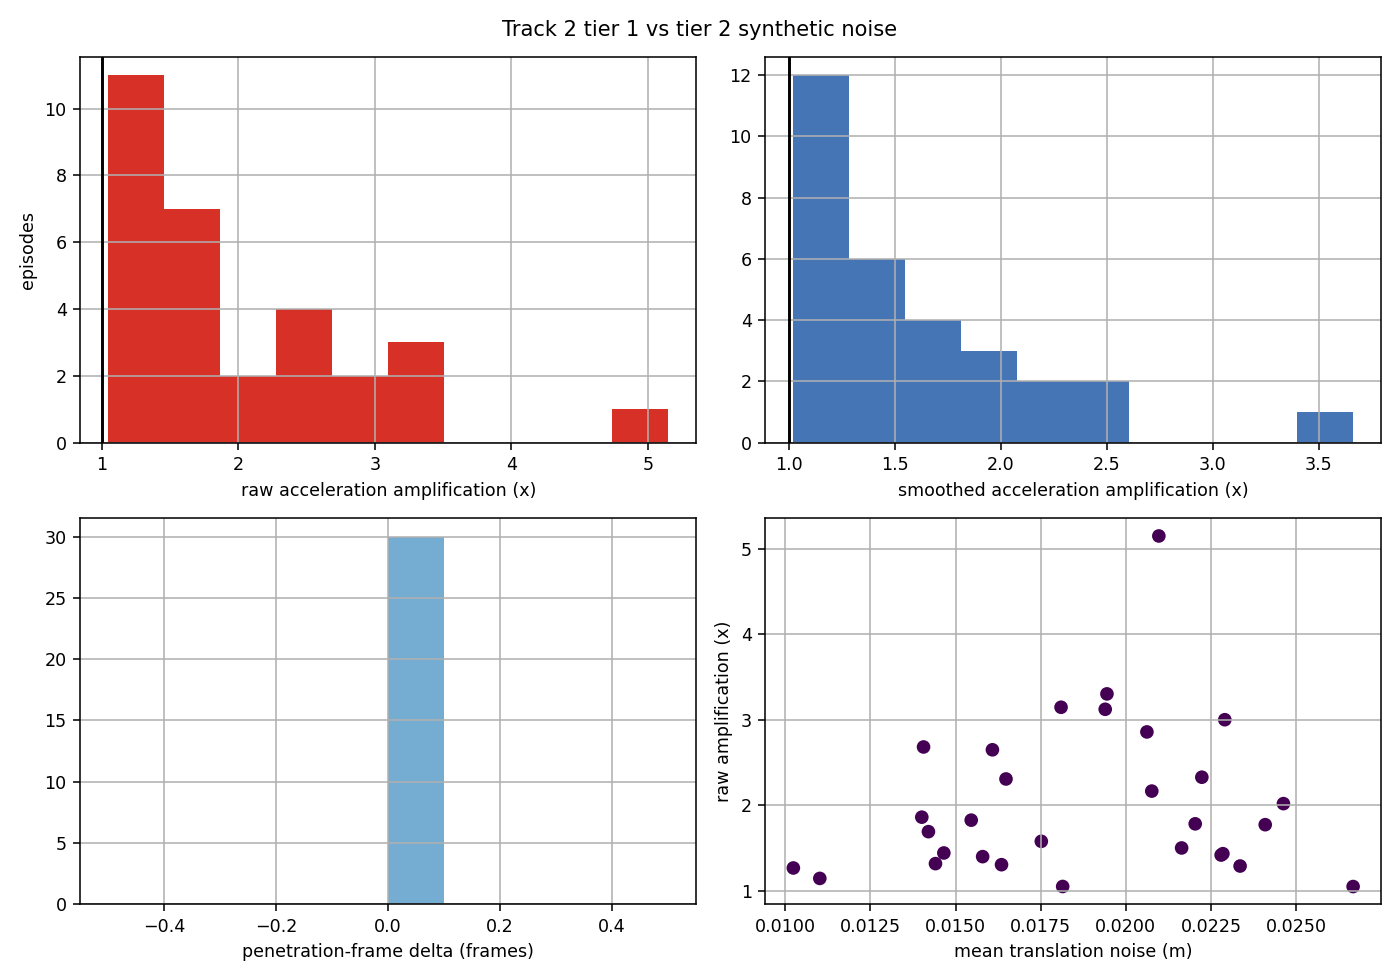

In [7]:
from pathlib import Path
import json, sys, time, platform, subprocess, importlib.util
import matplotlib; matplotlib.use('Agg', force=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'v2d_cpu_utils.py').exists(): ROOT=Path('/Users/luran/Desktop/V2D_Challenge')
sys.path.insert(0,str(ROOT))
from v2d_cpu_utils import *
paths=ensure_outputs()
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'font.size':9})

fig,ax=plt.subplots(2,2,figsize=(10,7)); ax[0,0].hist(sdf.acceleration_amplification_raw_x,bins=10,color='#d73027'); ax[0,0].axvline(1,color='k'); ax[0,0].set_xlabel('raw acceleration amplification (x)'); ax[0,0].set_ylabel('episodes'); ax[0,1].hist(sdf.acceleration_amplification_smoothed_x,bins=10,color='#4575b4'); ax[0,1].axvline(1,color='k'); ax[0,1].set_xlabel('smoothed acceleration amplification (x)'); ax[1,0].hist(sdf.penetration_delta_frames,bins=10,color='#74add1'); ax[1,0].set_xlabel('penetration-frame delta (frames)'); ax[1,1].scatter(sdf.mean_translation_noise_m,sdf.acceleration_amplification_raw_x,c=sdf.contact_shift_frames.fillna(0),cmap='viridis'); ax[1,1].set_xlabel('mean translation noise (m)'); ax[1,1].set_ylabel('raw amplification (x)'); fig.suptitle('Track 2 tier 1 vs tier 2 synthetic noise'); fig.tight_layout(); fig.savefig(paths['figs']/'track2_noise_comparison.png',dpi=140); plt.close(fig); display(Image(filename=str(paths['figs']/'track2_noise_comparison.png')))

### Pinocchio CPU kinematic feasibility check

**What it does.** Loads the bundled G1 `main_nodex.urdf` with the named `v2d` interpreter and runs damped least-squares position IK for a left wrist frame. Tier trajectories are mapped to bounded target motion. This is a retargeting feasibility surrogate, not simulation.

**Input.** Track 2 object trajectories and G1 URDF.

**Output.** `outputs/report/pinocchio_retarget.json`.

**References.** Pinocchio: https://github.com/stack-of-tasks/pinocchio ; starter assets under `video_to_data/robotic_grounding/`.

In [9]:
from pathlib import Path
import json, sys, time, platform, subprocess, importlib.util
import matplotlib; matplotlib.use('Agg', force=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'v2d_cpu_utils.py').exists(): ROOT=Path('/Users/luran/Desktop/V2D_Challenge')
sys.path.insert(0,str(ROOT))
from v2d_cpu_utils import *
paths=ensure_outputs()
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'font.size':9})

urdf=ROOT/'video_to_data/robotic_grounding/source/robotic_grounding/robotic_grounding/assets/urdfs/g1/main_nodex.urdf'; script="""import json,sys,numpy as np
import pinocchio as pin
from pathlib import Path
model=pin.buildModelFromUrdf(sys.argv[1]); data=model.createData(); fid=model.getFrameId('left_wrist_roll_link'); q=pin.neutral(model); pin.framesForwardKinematics(model,data,q); p0=data.oMf[fid].translation.copy(); out=[]
for path in sys.argv[2:]:
 d=np.load(path); target=p0[None,:]+0.45*(d-d[0]); qk=q.copy(); ok=[]; errs=[]
 for t in target[::max(1,len(target)//80)]:
  for _ in range(35):
   pin.framesForwardKinematics(model,data,qk); e=t-data.oMf[fid].translation; J=pin.computeFrameJacobian(model,data,qk,fid,pin.LOCAL_WORLD_ALIGNED)[:3]; dq=J.T@np.linalg.solve(J@J.T+1e-4*np.eye(3),e); qk=pin.integrate(model,qk,0.25*dq); qk=np.minimum(np.maximum(qk,model.lowerPositionLimit),model.upperPositionLimit)
  pin.framesForwardKinematics(model,data,qk); errs.append(np.linalg.norm(t-data.oMf[fid].translation)); ok.append(errs[-1]<.04)
 out.append({'path':path,'sampled_targets':len(ok),'reachable_rate':float(np.mean(ok)),'mean_position_error_m':float(np.mean(errs)),'joint_limit_hit_rate':float(np.mean((qk<=model.lowerPositionLimit+1e-5)|(qk>=model.upperPositionLimit-1e-5))),'model_nq':int(model.nq)})
print(json.dumps(out))"""; sp=paths['logs']/'pinocchio_ik.py'; sp.write_text(script); arr=[]
for a in t21[:3]:
 d=read_parquet(a['parquet']); f=paths['logs']/f"tier1_{a['episode_index']}.npy"; np.save(f,np.vstack(d['observation.object.pose'].to_numpy())[:,:3]); arr.append(str(f))
try:
 res=subprocess.run(['/opt/anaconda3/envs/v2d/bin/python',str(sp),str(urdf),*arr],capture_output=True,text=True,timeout=90,check=True); pinres=json.loads(res.stdout); status='Pinocchio IK executed with the named v2d interpreter.'
except Exception as exc: pinres={'error':f'{type(exc).__name__}: {exc}','urdf':str(urdf)}; status=f'Pinocchio subprocess failed: {type(exc).__name__}: {exc}'
write_json(paths['report']/'pinocchio_retarget.json',{'status':status,'results':pinres}); print(status); display(pd.DataFrame(pinres if isinstance(pinres,list) else [pinres]))

Pinocchio IK executed with the named v2d interpreter.


,path,sampled_targets,reachable_rate,mean_position_error_m,joint_limit_hit_rate,model_nq
0,/Users/luran/Desktop/V2D_Challenge/outputs/log...,87,1.000000,2.301524e-07,0.000000,29
1,/Users/luran/Desktop/V2D_Challenge/outputs/log...,83,0.879518,1.500366e-02,0.137931,29
2,/Users/luran/Desktop/V2D_Challenge/outputs/log...,82,0.634146,7.093954e-02,0.068966,29


### Track 2 conclusion and artifact manifest

**What it does.** Produces an English evidence table for noise amplification, contact uncertainty, retargeting feasibility, and the no-policy scope.

**Input.** Track 2 summary and Pinocchio result.

**Output.** `outputs/report/track2_conclusion.json`.

**References.** NVIDIA V2D Challenge: https://nvidia-isaac.github.io/video_to_data/v2d_challenge/

In [11]:
from pathlib import Path
import json, sys, time, platform, subprocess, importlib.util
import matplotlib; matplotlib.use('Agg', force=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'v2d_cpu_utils.py').exists(): ROOT=Path('/Users/luran/Desktop/V2D_Challenge')
sys.path.insert(0,str(ROOT))
from v2d_cpu_utils import *
paths=ensure_outputs()
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'font.size':9})

pinr=json.loads((paths['report']/'pinocchio_retarget.json').read_text()); concl={'episodes':len(sdf),'median_raw_acceleration_amplification_x':float(sdf.acceleration_amplification_raw_x.median()),'median_smoothed_acceleration_amplification_x':float(sdf.acceleration_amplification_smoothed_x.median()),'median_penetration_delta_frames':float(sdf.penetration_delta_frames.median()),'contact_shift_non_null_episodes':int(sdf.contact_shift_frames.notna().sum()),'pinocchio_status':pinr['status'],'policy_training':'not run: Isaac Lab and RL are outside CPU-only scope','interpretation':'Tier 2 perturbations expose second-difference amplification and contact-frame uncertainty; smoothing reduces derivative spikes but cannot restore missing contact geometry.'}; write_json(paths['report']/'track2_conclusion.json',concl); display(pd.DataFrame([concl]).T.rename(columns={0:'value'}))

,value
episodes,30
median_raw_acceleration_amplification_x,1.776972
median_smoothed_acceleration_amplification_x,1.404829
median_penetration_delta_frames,0.0
contact_shift_non_null_episodes,0
pinocchio_status,Pinocchio IK executed with the named v2d inter...
policy_training,not run: Isaac Lab and RL are outside CPU-only...
interpretation,Tier 2 perturbations expose second-difference ...
